# Informative look at Data From 2023-2025

This code takes a look at the public data provide from "https://cde.ucr.cjis.gov/LATEST/webapp/#/pages/home". Taking the data they have provided I first started to combine all of the relevant files that can be combined so that I can view them through one data set. 





In [44]:
import pandas as pd

# Here is my process incase you wanted to observe but you would need the files inorder to replicate.
# I first started by combing through to get "TYPE" charts. These are used for code identification and clarification.
#I moved them at the very begining to a folder labled KS-2023-2025.
#This shows the process for one file but this process was completed with a much bigger function to combine 19 different times. 

df1 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023\NIBRS_CRIMINAL_ACT.csv")
df2 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\NIBRS_CRIMINAL_ACT.csv")
df3 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2025\NIBRS_CRIMINAL_ACT.csv")

combined = pd.concat([df1, df2, df3], ignore_index=True)


combined.to_csv(
    r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_CRIMINAL_ACT_COMBINED.csv",
    index=False
)


print("Files successfully combined!")



Files successfully combined!


In [10]:
#import numpy as np
#import seaborn as sns

import pandas as pd

 
df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_ARRESTEE_COMBINED.csv")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117824 entries, 0 to 117823
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   data_year                  117824 non-null  int64  
 1   arrestee_id                117824 non-null  int64  
 2   incident_id                117824 non-null  int64  
 3   arrestee_seq_num           117824 non-null  int64  
 4   arrest_date                117824 non-null  object 
 5   arrest_type_id             117824 non-null  int64  
 6   multiple_indicator         117824 non-null  object 
 7   offense_code               117824 non-null  object 
 8   age_id                     117824 non-null  int64  
 9   age_num                    117824 non-null  int64  
 10  sex_code                   117824 non-null  object 
 11  race_id                    117824 non-null  int64  
 12  ethnicity_id               117824 non-null  int64  
 13  resident_code              11

In [24]:
import pandas as pd


df1 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_ARRESTEE_COMBINED.csv")
df2 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_ARREST_TYPE.csv")


merged_df = pd.merge(df1, df2, on="arrest_type_id", how="inner")


merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]


merged_df.to_csv(r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_ARRESTEE_COMBINED_TYPE.csv", index=False)

print("Files successfully combined!")

Files successfully combined!


In [27]:
import numpy as np
import seaborn as sns
import pandas as pd

 
df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_ARRESTEE_COMBINED_TYPE.csv")


df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117824 entries, 0 to 117823
Data columns (total 20 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   data_year                  117824 non-null  int64  
 1   arrestee_id                117824 non-null  int64  
 2   incident_id                117824 non-null  int64  
 3   arrestee_seq_num           117824 non-null  int64  
 4   arrest_date                117824 non-null  object 
 5   arrest_type_id             117824 non-null  int64  
 6   multiple_indicator         117824 non-null  object 
 7   offense_code               117824 non-null  object 
 8   age_id                     117824 non-null  int64  
 9   age_num                    117824 non-null  int64  
 10  sex_code                   117824 non-null  object 
 11  race_id                    117824 non-null  int64  
 12  ethnicity_id               117824 non-null  int64  
 13  resident_code              11

In [68]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_ARRESTEE_COMBINED_TYPE_OFFENSE.csv")



sns.set_theme(style="whitegrid", palette="muted")


df["arrest_date"] = pd.to_datetime(
    df["arrest_date"],
    errors="coerce"
)


df["month"] = df["arrest_date"].dt.month


df["month_name"] = df["arrest_date"].dt.month_name()

print(df.info())
print(df["data_year"].value_counts().sort_index())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117824 entries, 0 to 117823
Data columns (total 29 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   data_year                  117824 non-null  int64         
 1   arrestee_id                117824 non-null  int64         
 2   incident_id                117824 non-null  int64         
 3   arrestee_seq_num           117824 non-null  int64         
 4   arrest_date                117824 non-null  datetime64[ns]
 5   arrest_type_id             117824 non-null  int64         
 6   multiple_indicator         117824 non-null  object        
 7   offense_code               117824 non-null  object        
 8   age_id                     117824 non-null  int64         
 9   age_num                    117824 non-null  int64         
 10  sex_code                   117824 non-null  object        
 11  race_id                    117824 non-null  int64   

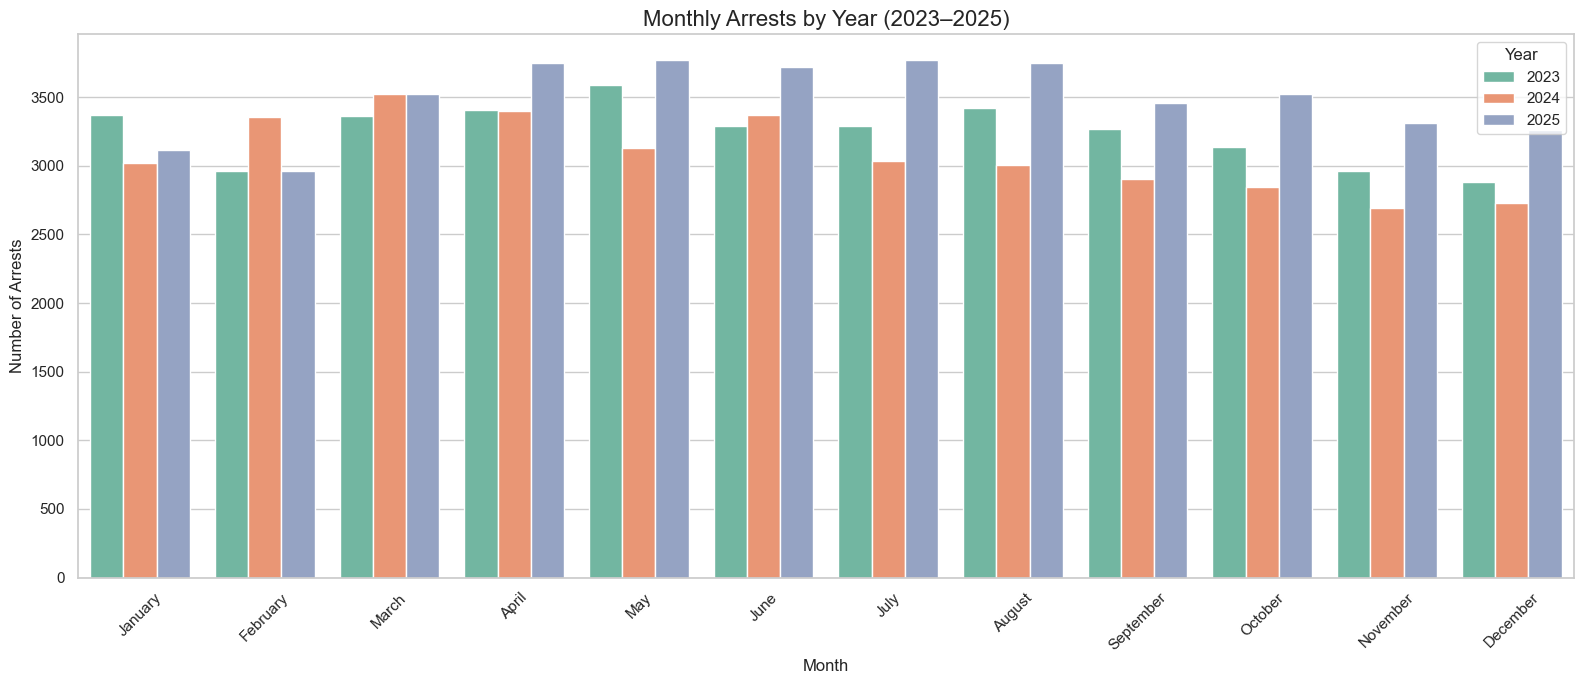

In [66]:

monthly_arrests = df.groupby(
    ["data_year", "month"]
).size().reset_index(name="arrest_count")


monthly_arrests["month_name"] = pd.to_datetime(
    monthly_arrests["month"],
    format="%m"
).dt.month_name()


plt.figure(figsize=(16, 7))

sns.barplot(
    data=monthly_arrests,
    x="month_name",
    y="arrest_count",
    hue="data_year",
    palette="Set2",
    order=[
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ]
)

plt.title("Monthly Arrests by Year (2023–2025)", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Arrests", fontsize=12)

plt.xticks(rotation=45)
plt.legend(title="Year")
plt.tight_layout()
# Create chart

plt.show()


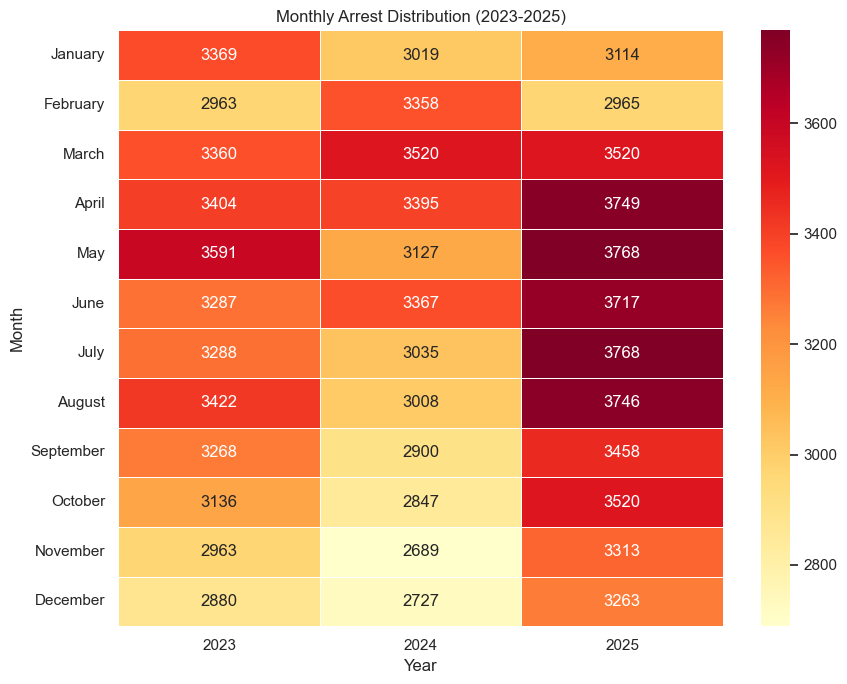

In [253]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\NIBRS_ARRESTEE_COMBINED_TYPE_OFFENSE.csv")


sns.set_theme(style="whitegrid", palette="muted")
# Style

df["arrest_date"] = pd.to_datetime(
    df["arrest_date"],
    errors="coerce"
)


df["month"] = df["arrest_date"].dt.month

df["month_name"] = df["arrest_date"].dt.month_name() 

monthly_arrests = df.groupby(
    ["data_year", "month"]
).size().reset_index(name="arrest_count")


monthly_arrests["month_name"] = pd.to_datetime(
    monthly_arrests["month"],
    format="%m"
).dt.month_name()

import calendar

monthly_data = df.pivot_table(
    index="month",
    columns="data_year",
    values="arrestee_id",
    aggfunc="count"
)

monthly_data.index = monthly_data.index.map(lambda x: calendar.month_name[int(x)])

plt.figure(figsize=(9, 7))

sns.heatmap(
    monthly_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Monthly Arrest Distribution (2023-2025)")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()
plt.show()

In [94]:
#getting an idea of what violations are prevalent 
print(df["offense_code"].value_counts())

offense_code
35A    31640
13B    26107
23C    12852
13A     8546
290     6733
35B     5854
13C     4990
520     2433
23H     2403
220     2123
90Z     2076
280     1485
23D     1288
90D     1256
240     1189
23F      797
120      763
26A      703
100      680
11D      390
250      386
90J      375
90C      359
90G      347
11A      295
09A      257
200      239
26B      228
90F      177
40B      157
270      141
23G      112
370      103
40A       83
11B       66
23B       62
26C       37
23E       21
23A       21
09B       19
210       14
36B       12
510        3
36A        1
26D        1
Name: count, dtype: int64


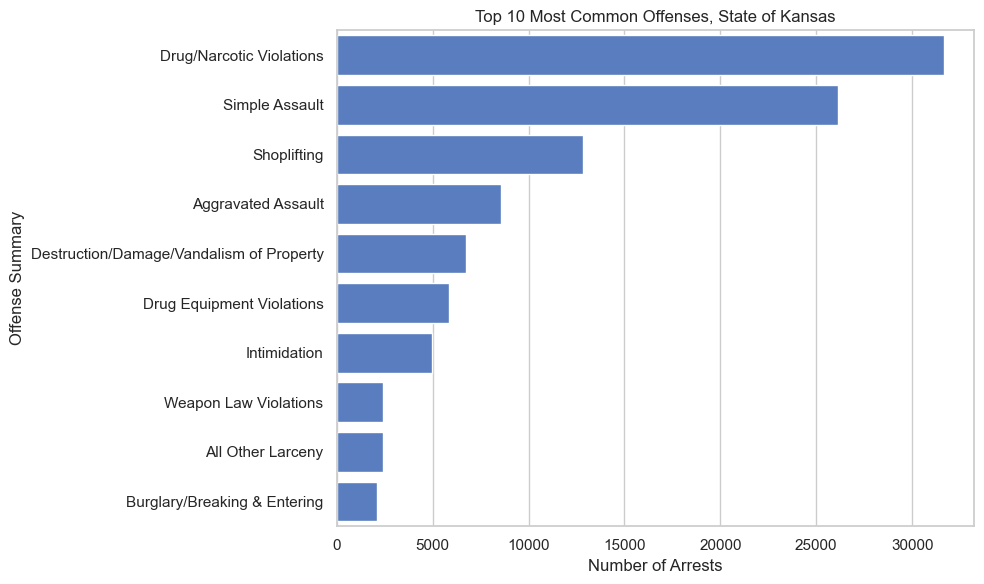

In [255]:
plt.figure(figsize=(10, 6))

top_offenses = df["offense_name"].value_counts().head(10)

sns.barplot(
    x=top_offenses.values,
    y=top_offenses.index
)

plt.title("Top 10 Most Common Offenses, State of Kansas")
plt.xlabel("Number of Arrests")
plt.ylabel("Offense Summary")

plt.tight_layout()
plt.show()


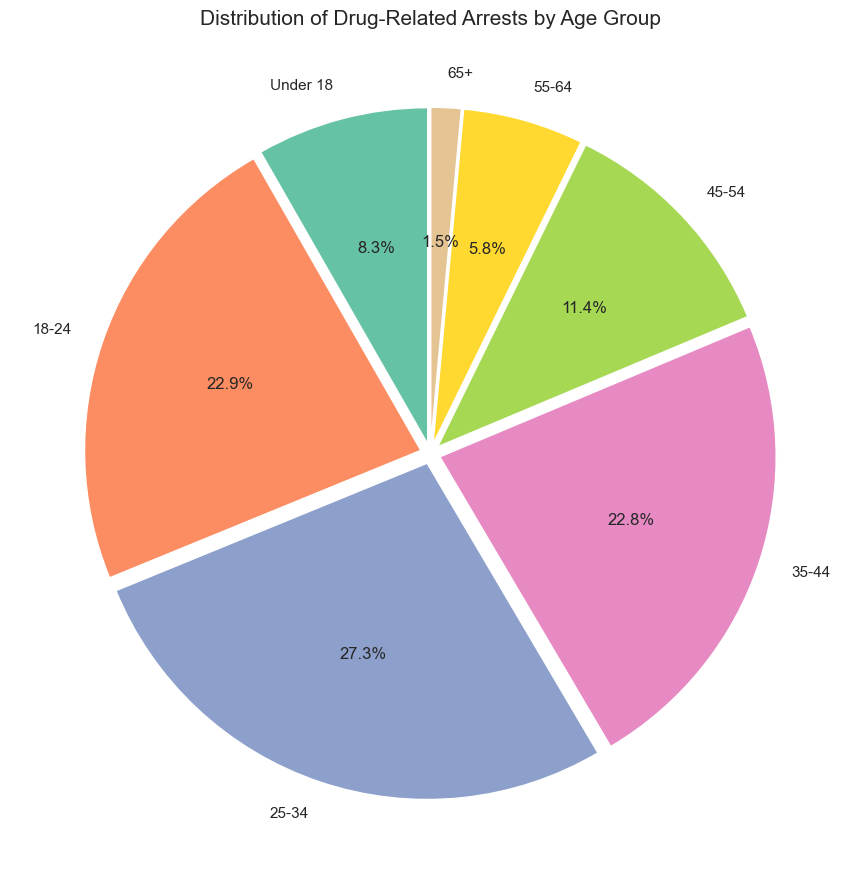

In [86]:

drug_df = df[df["offense_code"] == "35A"].copy()

bins = [0, 17, 24, 34, 44, 54, 64, 120]

labels = [
    "Under 18",
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

drug_df["age_group"] = pd.cut(
    drug_df["age_num"],
    bins=bins,
    labels=labels
)

age_distribution = drug_df["age_group"].value_counts().sort_index()

plt.figure(figsize=(9, 9))

plt.pie(
    age_distribution,
    labels=age_distribution.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2"),
    explode=[0.03] * len(age_distribution)
)

plt.title(
    "Distribution of Drug-Related Arrests by Age Group",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [122]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\main2.csv")

for col in df.columns:
    print(col)

data_year_x
arrestee_id
incident_id
arrestee_seq_num
arrest_date
arrest_type_id
multiple_indicator
offense_code
age_id
age_num
sex_code
race_id
ethnicity_id
resident_code
under_18_disposition_code
clearance_ind
age_range_low_num
age_range_high_num
arrest_type_code
arrest_type_name
offense_name
crime_against
ct_flag
hc_flag
hc_code
offense_category_name
offense_group
data_year_y
agency_id
nibrs_month_id
cargo_theft_flag
submission_date
incident_date
report_date_flag
incident_hour
cleared_except_id
cleared_except_date
incident_status
data_home
orig_format
did
yearly_agency_id
data_year
ori
legacy_ori
covered_by_legacy_ori
direct_contributor_flag
dormant_flag
dormant_year
reporting_type
ucr_agency_name
ncic_agency_name
pub_agency_name
pub_agency_unit
agency_status
state_id
state_name
state_abbr
state_postal_abbr
division_code
division_name
region_code
region_name
region_desc
agency_type_name
population
submitting_agency_id
sai
submitting_agency_name
suburban_area_flag
population_group_id


C:\Users\jason\AppData\Local\Temp\ipykernel_36136\1832535696.py:6: DtypeWarning: Columns (36,53,89,90,91,92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\main2.csv")


In [125]:
import pandas as pd

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Main2.csv")

sedgwick_df = df[
    df["county_name"].str.contains("Sedgwick", case=False, na=False)
].copy()

# Export to a new CSV file
sedgwick_df.to_csv(
    r"C:\Users\jason\Downloads\KS-2023-2025\Sedgwick_County_Crime_Data.csv",
    index=False
)

# Display results
print("Export complete!")
print("Total records:", len(sedgwick_df))
print("Total columns:", len(sedgwick_df.columns))

C:\Users\jason\AppData\Local\Temp\ipykernel_36136\2902528583.py:3: DtypeWarning: Columns (36,53,89,90,91,92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Main2.csv")


Export complete!
Total records: 23669
Total columns: 99


C:\Users\jason\AppData\Local\Temp\ipykernel_8836\3890151747.py:6: DtypeWarning: Columns (36) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Sedgwick_County_Crime_Data.csv")


<Figure size 1100x700 with 0 Axes>

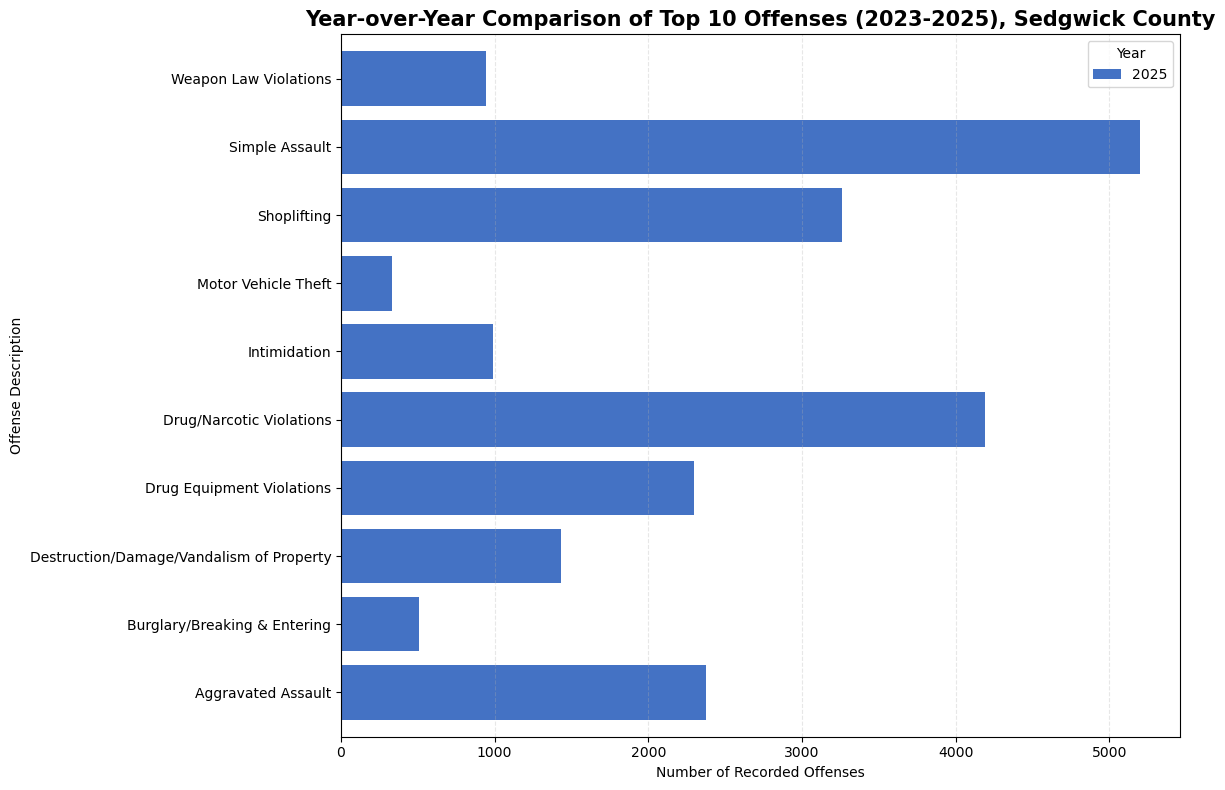

In [55]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Sedgwick_County_Crime_Data.csv")
plt.figure(figsize=(11, 7))


top_10 = df["offense_name"].value_counts().head(10).index


filtered_df = df[df["offense_name"].isin(top_10)]


yearly_offenses = pd.crosstab(
    filtered_df["offense_name"],
    filtered_df["data_year"]
)


yearly_offenses.plot(
    kind="barh",
    figsize=(12, 8),
    width=0.8,
    color=["#4472C4", "#ED7D31", "#70AD47"]
)

plt.title(
    "Year-over-Year Comparison of Top 10 Offenses (2023-2025), Sedgwick County",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Recorded Offenses")
plt.ylabel("Offense Description")

plt.legend(title="Year")
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [133]:
import pandas as pd

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Sedgwick_County_Crime_Data.csv")

sedgwick_df = df[
    df["ucr_agency_name"].str.contains("WICHITA", case=False, na=False)
].copy()

# Export to a new CSV file
sedgwick_df.to_csv(
    r"C:\Users\jason\Downloads\KS-2023-2025\Wichita_Crime_Data.csv",
    index=False
)
print("Files successfully combined!")

C:\Users\jason\AppData\Local\Temp\ipykernel_36136\2977980932.py:3: DtypeWarning: Columns (36) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Sedgwick_County_Crime_Data.csv")


Files successfully combined!


<Figure size 1000x600 with 0 Axes>

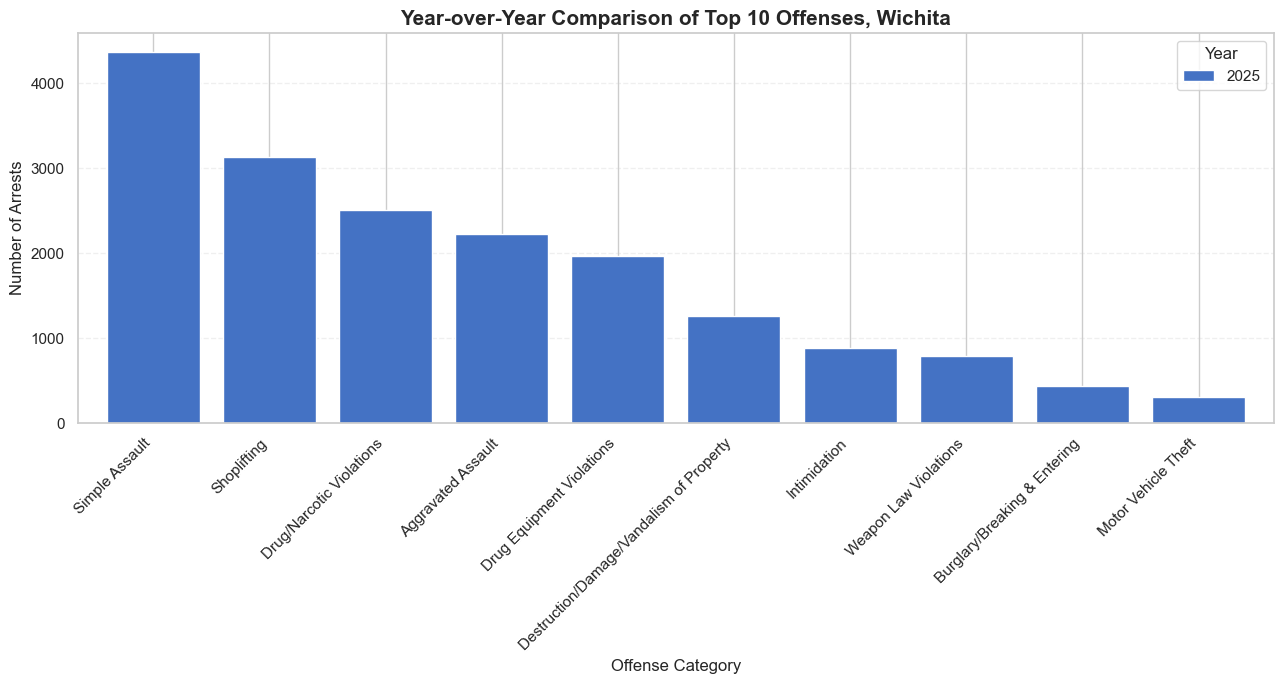

In [257]:
# Now we have narrowed down our data to Sedgwick county
# lets see how Sedgwick county compares to the rest of the state
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Wichita_Crime_Data.csv")
plt.figure(figsize=(10, 6))

# Count offenses by year
yearly_offenses = df.pivot_table(
    index="offense_name",
    columns="data_year",
    values="arrestee_id",
    aggfunc="count"
)

# Select top 10 offenses overall
top_10 = yearly_offenses.sum(axis=1).nlargest(10).index

yearly_offenses = yearly_offenses.loc[top_10]

# Create grouped bar chart
ax = yearly_offenses.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8,
    color=["#4472C4", "#ED7D31", "#70AD47"]
)

plt.title(
    "Year-over-Year Comparison of Top 10 Offenses, Wichita",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Offense Category")
plt.ylabel("Number of Arrests")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Year")
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

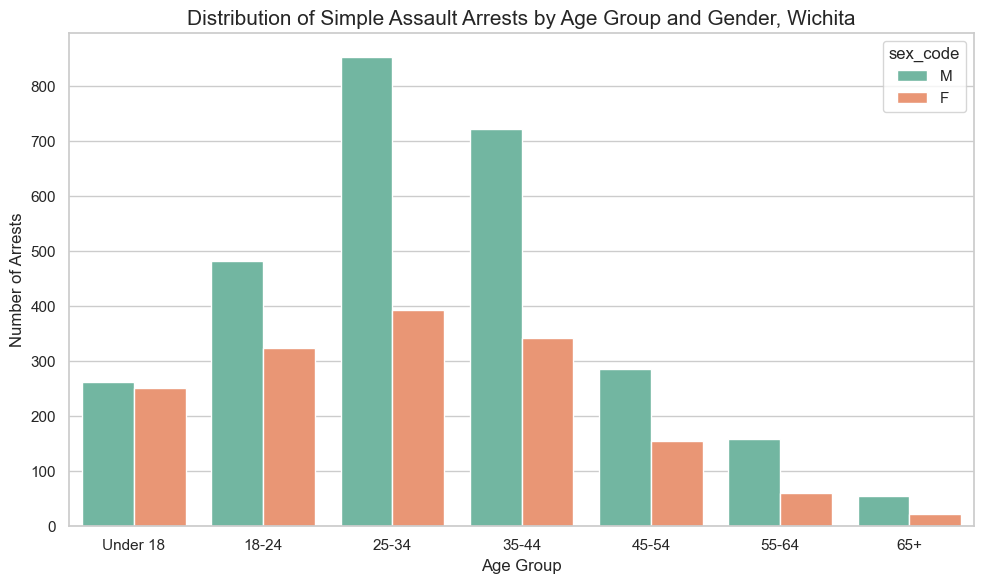

In [259]:
assault_df = df[df["offense_code"] == "13B"].copy()


bins = [0, 17, 24, 34, 44, 54, 64, 120]
labels = [
    "Under 18",
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

assault_df["age_group"] = pd.cut(
    assault_df["age_num"],
    bins=bins,
    labels=labels,
    include_lowest=True
)


plt.figure(figsize=(10, 6))


sns.countplot(
    data=assault_df,
    x="age_group",
    hue="sex_code",
    palette="Set2",
    order=labels
)

plt.title("Distribution of Simple Assault Arrests by Age Group and Gender, Wichita", fontsize=15)
plt.xlabel("Age Group")
plt.ylabel("Number of Arrests")
plt.legend(title="sex_code")
plt.tight_layout()
plt.show()


In [16]:
df=df.astype({'ncic_agency_name' : float})
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 0 entries
Data columns (total 59 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   yearly_agency_id                0 non-null      int64  
 1   agency_id                       0 non-null      int64  
 2   data_year                       0 non-null      int64  
 3   ori                             0 non-null      object 
 4   legacy_ori                      0 non-null      object 
 5   covered_by_legacy_ori           0 non-null      object 
 6   direct_contributor_flag         0 non-null      object 
 7   dormant_flag                    0 non-null      object 
 8   dormant_year                    0 non-null      float64
 9   reporting_type                  0 non-null      object 
 10  ucr_agency_name                 0 non-null      object 
 11  ncic_agency_name                0 non-null      float64
 12  pub_agency_name                 0 non-null      objec

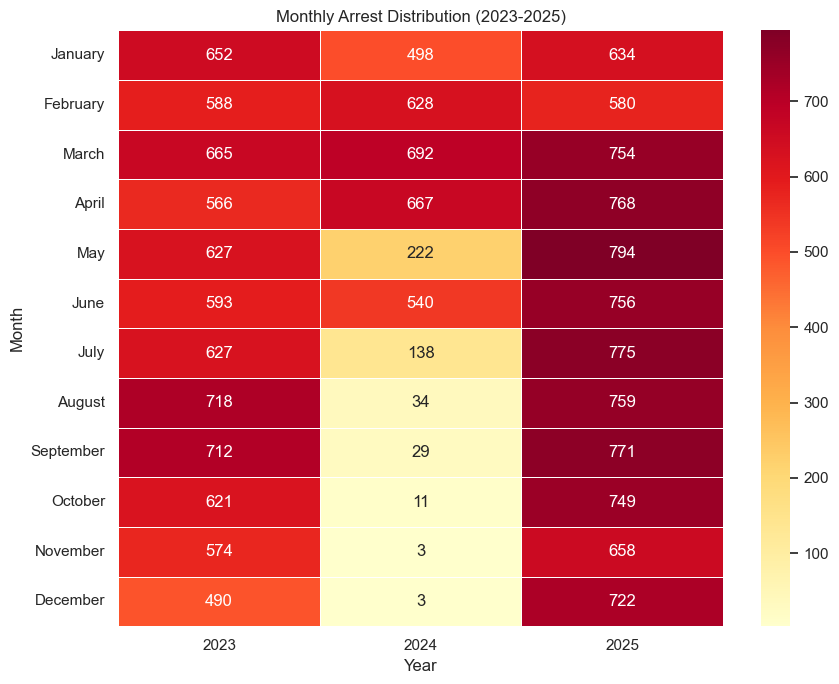

In [195]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2023-2025\Wichita_Crime_Data.csv")
# Load dataset


sns.set_theme(style="whitegrid", palette="muted")
# Style

df["arrest_date"] = pd.to_datetime(
    df["arrest_date"],
    errors="coerce"
)
# Convert arrest_date to datetime

df["month"] = df["arrest_date"].dt.month
# Getting month

df["month_name"] = df["arrest_date"].dt.month_name() 

monthly_arrests = df.groupby(
    ["data_year_x", "month"]
).size().reset_index(name="arrest_count")


monthly_arrests["month_name"] = pd.to_datetime(
    monthly_arrests["month"],
    format="%m"
).dt.month_name()

import calendar

monthly_data = df.pivot_table(
    index="month",
    columns="data_year_x",
    values="arrestee_id",
    aggfunc="count"
)

monthly_data.index = monthly_data.index.map(lambda x: calendar.month_name[int(x)])

plt.figure(figsize=(9, 7))

sns.heatmap(
    monthly_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Monthly Arrest Distribution (2023-2025)")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()
plt.show()

In [219]:
!pip install folium geopy pandas


In [225]:
import pandas as pd
import folium
import numpy as np
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import time

df = pd.read_csv(
    r"C:\Users\jason\Downloads\KS-2023-2025\Main2.csv"
)

agency_crimes = (
    df.groupby("pub_agency_name")["incident_id"]
    .nunique()
    .reset_index(name="Crime_Count")
)


total_incidents = df["incident_id"].nunique()

agency_crimes["Percentage"] = (
    agency_crimes["Crime_Count"] / total_incidents
) * 100


top_10 = agency_crimes.sort_values(
    "Crime_Count",
    ascending=False
).head(10)

print(top_10)

    pub_agency_name  Crime_Count  Percentage
266         Wichita        18224   17.081584
193          Olathe         5861    5.493589
250          Topeka         5291    4.959321
201   Overland Park         5122    4.800915
138     Kansas City         3752    3.516797
236         Shawnee         3304    3.096881
230          Salina         3153    2.955346
124      Hutchinson         2838    2.660093
152        Lawrence         2598    2.435138
155          Lenexa         2566    2.405144


C:\Users\jason\AppData\Local\Temp\ipykernel_36136\2681620712.py:8: DtypeWarning: Columns (36,53,89,90,91,92) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


In [227]:
print(
    df[["pub_agency_name", "county_name"]]
    .drop_duplicates()
    .sort_values("pub_agency_name")
    .head(50)
)

                   pub_agency_name             county_name
463                        Abilene               DICKINSON
0                            Allen                   ALLEN
37665                         Alma               WABAUNSEE
353                       Anderson                ANDERSON
3153                       Andover                  BUTLER
9106                       Anthony                  HARPER
5094                 Arkansas City                  COWLEY
78854                         Arma                CRAWFORD
621                       Atchison                ATCHISON
43965                       Attica                  HARPER
12935                       Atwood                 RAWLINS
2612                       Augusta                  BUTLER
2317                  Baldwin City                 DOUGLAS
776                         Barber                  BARBER
799                         Barton                  BARTON
28204                      Basehor             LEAVENWOR

In [231]:

city_coordinates = {
    "Wichita": (37.6922, -97.3375),
    "Olathe": (38.8814, -94.8191),
    "Topeka": (39.0483, -95.6780),
    "Overland Park": (38.9822, -94.6708),
    "Kansas City": (39.1142, -94.6275),
    "Shawnee": (39.0417, -94.7202),
    "Salina": (38.8403, -97.6114),
    "Hutchinson": (38.0608, -97.9298),
    "Lawrence": (38.9717, -95.2353),
    "Lenexa": (38.9536, -94.7336)
}


top_10["Latitude"] = top_10["pub_agency_name"].map(
    lambda x: city_coordinates[x][0]
)

top_10["Longitude"] = top_10["pub_agency_name"].map(
    lambda x: city_coordinates[x][1]
)

print(top_10)

    pub_agency_name  Crime_Count  Percentage  Latitude  Longitude
266         Wichita        18224   17.081584   37.6922   -97.3375
193          Olathe         5861    5.493589   38.8814   -94.8191
250          Topeka         5291    4.959321   39.0483   -95.6780
201   Overland Park         5122    4.800915   38.9822   -94.6708
138     Kansas City         3752    3.516797   39.1142   -94.6275
236         Shawnee         3304    3.096881   39.0417   -94.7202
230          Salina         3153    2.955346   38.8403   -97.6114
124      Hutchinson         2838    2.660093   38.0608   -97.9298
152        Lawrence         2598    2.435138   38.9717   -95.2353
155          Lenexa         2566    2.405144   38.9536   -94.7336


In [9]:

CARTO_API_KEY = "cb1_4zuk_1_735ff0b5a6c2e0fa0a41160f"


crime_map = folium.Map(
    location=[38.5, -98.0],
    zoom_start=7,
    tiles=None
)


folium.TileLayer(
    tiles=(
        "https://basemaps.cartocdn.com/"
        "rastertiles/voyager/{z}/{x}/{y}.png"
        f"?key={CARTO_API_KEY}"
    ),
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
    name="CARTO Voyager",
    overlay=False,
    control=True
).add_to(crime_map)


max_crimes = top_10["Crime_Count"].max()


for _, row in top_10.iterrows():

    
    radius = 7 + 20 * np.sqrt(
        row["Crime_Count"] / max_crimes
    )

    
    popup_text = f"""
    <div style="width:200px">
        <h4>{row['pub_agency_name']}, Kansas</h4>
        <b>Recorded Incidents:</b> {row['Crime_Count']:,}<br>
        <b>Statewide Share:</b> {row['Percentage']:.2f}%
    </div>
    """


    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=radius,
        color="#8B0000",
        weight=2,
        fill=True,
        fill_color="#E63946",
        fill_opacity=0.65,
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=f"{row['pub_agency_name']}: {row['Percentage']:.2f}%"
    ).add_to(crime_map)

    
    folium.Marker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        icon=folium.DivIcon(
            html=f"""
            <div style="
                font-size: 20px;
                font-weight: bold;
                color: #222;
                white-space: nowrap;
                text-shadow: 1px 1px 2px white;
                margin-left: 12px;
                margin-top: -10px;
            ">
                {row['Percentage']:.2f}%
            </div>
            """
        )
    ).add_to(crime_map)


crime_map.fit_bounds(
    [
        [top_10["Latitude"].min() - 0.3,
         top_10["Longitude"].min() - 0.3],

        [top_10["Latitude"].max() + 0.3,
         top_10["Longitude"].max() + 0.3]
    ]
)


NameError: name 'folium' is not defined

In [241]:
import requests

url = "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json"

response = requests.get(url)
states_geojson = response.json()


kansas = {
    "type": "FeatureCollection",
    "features": [
        feature for feature in states_geojson["features"]
        if feature["properties"]["name"] == "Kansas"
    ]
}

In [53]:

import pandas as pd
import folium
import numpy as np
import requests


df = pd.read_csv(
    r"C:\Users\jason\Downloads\KS-2023-2025\Main2.csv",
    low_memory=False
)


agency_crimes = (
    df.groupby("pub_agency_name")["incident_id"]
    .nunique()
    .reset_index(name="Crime_Count")
)

total_incidents = df["incident_id"].nunique()

agency_crimes["Percentage"] = (
    agency_crimes["Crime_Count"] / total_incidents
) * 100

top_10 = agency_crimes.sort_values(
    "Crime_Count",
    ascending=False
).head(10).copy()


city_coordinates = {
    "Wichita": (37.6922, -97.3375),
    "Olathe": (38.8814, -94.8191),
    "Topeka": (39.0483, -95.6780),
    "Overland Park": (38.9822, -94.6708),
    "Kansas City": (39.1142, -94.6275),
    "Shawnee": (39.0417, -94.7202),
    "Salina": (38.8403, -97.6114),
    "Hutchinson": (38.0608, -97.9298),
    "Lawrence": (38.9717, -95.2353),
    "Lenexa": (38.9536, -94.7336)
}

top_10["Latitude"] = top_10["pub_agency_name"].map(
    lambda x: city_coordinates[x][0]
)

top_10["Longitude"] = top_10["pub_agency_name"].map(
    lambda x: city_coordinates[x][1]
)

label_offsets = {
    "Wichita": (0.25, 0.35),
    "Olathe": (0.30, -0.55),
    "Topeka": (0.30, 0.35),
    "Overland Park": (0.45, 0.35),
    "Kansas City": (0.55, 0.55),
    "Shawnee": (-0.30, -0.45),
    "Salina": (0.25, 0.35),
    "Hutchinson": (-0.30, -0.40),
    "Lawrence": (0.30, 0.50),
    "Lenexa": (-0.45, 0.30)
}


CARTO_API_KEY = "cb1_4zuk_1_735ff0b5a6c2e0fa0a41160f"

crime_map = folium.Map(
    location=[38.5, -98.0],
    zoom_start=7,
    tiles=None
)

folium.TileLayer(
    tiles=(
        "https://basemaps.cartocdn.com/"
        "rastertiles/voyager/{z}/{x}/{y}.png"
        f"?key={CARTO_API_KEY}"
    ),
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors &copy; <a href="https://carto.com/attributions">CARTO</a>',
    name="CARTO Voyager",
    overlay=False,
    control=True
).add_to(crime_map)


max_crimes = top_10["Crime_Count"].max()

for _, row in top_10.iterrows():

    agency = row["pub_agency_name"]

    
    radius = 7 + 20 * np.sqrt(
        row["Crime_Count"] / max_crimes
    )

    
    popup_text = f"""
    <div style="width:250px; font-size:15px;">
        <h3 style="font-size:19px;">
            {agency}, Kansas
        </h3>
        <b>Recorded Incidents:</b> {row['Crime_Count']:,}<br>
        <b>Statewide Share:</b> {row['Percentage']:.2f}%
    </div>
    """

    
    folium.CircleMarker(
        location=[
            row["Latitude"],
            row["Longitude"]
        ],
        radius=radius,
        color="#8B0000",
        weight=2,
        fill=True,
        fill_color="#E63946",
        fill_opacity=0.65,
        popup=folium.Popup(
            popup_text,
            max_width=300
        ),
        tooltip=f"{agency}: {row['Percentage']:.2f}%"
    ).add_to(crime_map)

    
    lat_offset, lon_offset = label_offsets.get(
        agency,
        (0.12, 0.18)
    )

    label_lat = row["Latitude"] + lat_offset
    label_lon = row["Longitude"] + lon_offset

    
    folium.PolyLine(
        locations=[
            [row["Latitude"], row["Longitude"]],
            [label_lat, label_lon]
        ],
        color="#333333",
        weight=1.5,
        opacity=0.9
    ).add_to(crime_map)


    folium.Marker(
        location=[label_lat, label_lon],
        icon=folium.DivIcon(
            icon_size=(100, 30),
            icon_anchor=(0, 15),
            html=f"""
            <div style="
                font-size:16px;
                font-weight:bold;
                color:#222222;
                white-space:nowrap;
                background-color:transparent !important;
                border:none !important;
                border-radius:4px;
                padding:4px 7px;
                box-shadow:1px 1px 3px rgba(0,0,0,0.3);
            ">
                {row['Percentage']:.2f}%
            </div>
            """
        )
    ).add_to(crime_map)


crime_map.fit_bounds(
    [
        [
            top_10["Latitude"].min() - 0.5,
            top_10["Longitude"].min() - 0.5
        ],
        [
            top_10["Latitude"].max() + 0.5,
            top_10["Longitude"].max() + 0.5
        ]
    ]
)


url = (
    "https://raw.githubusercontent.com/"
    "PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

states_geojson = response.json()

kansas = {
    "type": "FeatureCollection",
    "features": [
        feature
        for feature in states_geojson["features"]
        if feature["properties"]["name"] == "Kansas"
    ]
}

folium.GeoJson(
    kansas,
    name="Kansas State Boundary",
    style_function=lambda feature: {
        "fillColor": "transparent",
        "color": "#202020",
        "weight": 3,
        "fillOpacity": 0,
        "opacity": 1
    }
).add_to(crime_map)

folium.LayerControl().add_to(crime_map)

crime_map


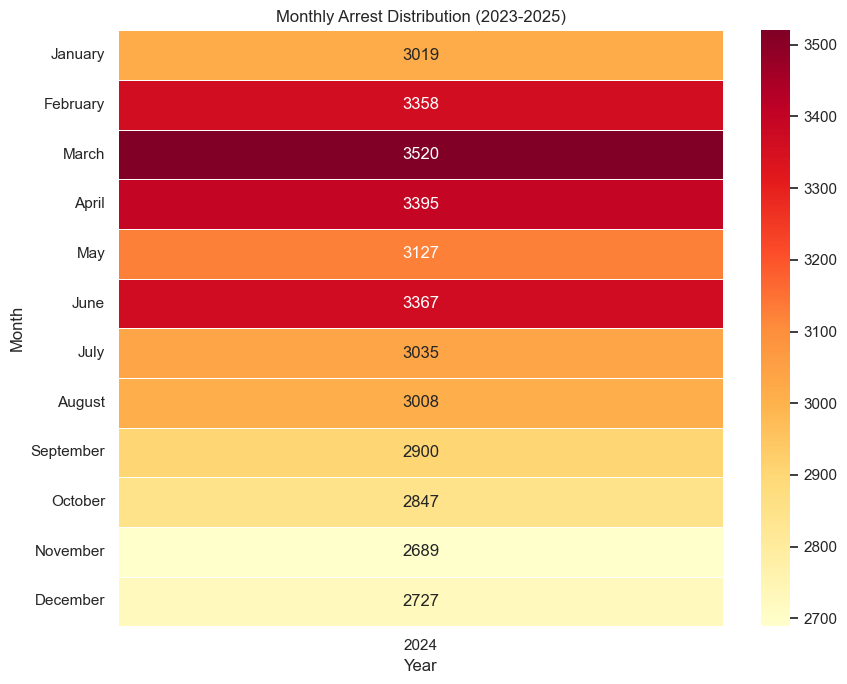

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\NIBRS_ARRESTEE.csv")


sns.set_theme(style="whitegrid", palette="muted")
# Style

df["arrest_date"] = pd.to_datetime(
    df["arrest_date"],
    errors="coerce"
)


df["month"] = df["arrest_date"].dt.month

df["month_name"] = df["arrest_date"].dt.month_name() 

monthly_arrests = df.groupby(
    ["data_year", "month"]
).size().reset_index(name="arrest_count")


monthly_arrests["month_name"] = pd.to_datetime(
    monthly_arrests["month"],
    format="%m"
).dt.month_name()

import calendar

monthly_data = df.pivot_table(
    index="month",
    columns="data_year",
    values="arrestee_id",
    aggfunc="count"
)

monthly_data.index = monthly_data.index.map(lambda x: calendar.month_name[int(x)])

plt.figure(figsize=(9, 7))

sns.heatmap(
    monthly_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Monthly Arrest Distribution (2023-2025)")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd


df1 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\New_Wichita.csv")
df2 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\agencies.csv")


merged_df = pd.merge(df1, df2, on="agency_id", how="inner")


merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]


merged_df.to_csv(r"C:\Users\jason\Downloads\KS-2024\New_Wichita.csv", index=False)

print("Files successfully combined!")

C:\Users\jason\AppData\Local\Temp\ipykernel_46048\1769683364.py:4: DtypeWarning: Columns (27,44,80,81,82,83) have mixed types. Specify dtype option on import or set low_memory=False.
  df1 = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\New_Wichita.csv")


MergeError: Passing 'suffixes' which cause duplicate columns {'data_year_x'} is not allowed.

In [15]:
import pandas as pd

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\New_Wichita.csv")

sedgwick_df = df[
    df["ucr_agency_name"].str.contains("WICHITA", case=False, na=False)
].copy()

# Export to a new CSV file
sedgwick_df.to_csv(
    r"C:\Users\jason\Downloads\KS-2024\Wichita_Crime_Data_2.csv",
    index=False
)
print("Files successfully combined!")

Files successfully combined!


C:\Users\jason\AppData\Local\Temp\ipykernel_46048\1123754774.py:3: DtypeWarning: Columns (27,44,80,81,82,83) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\New_Wichita.csv")


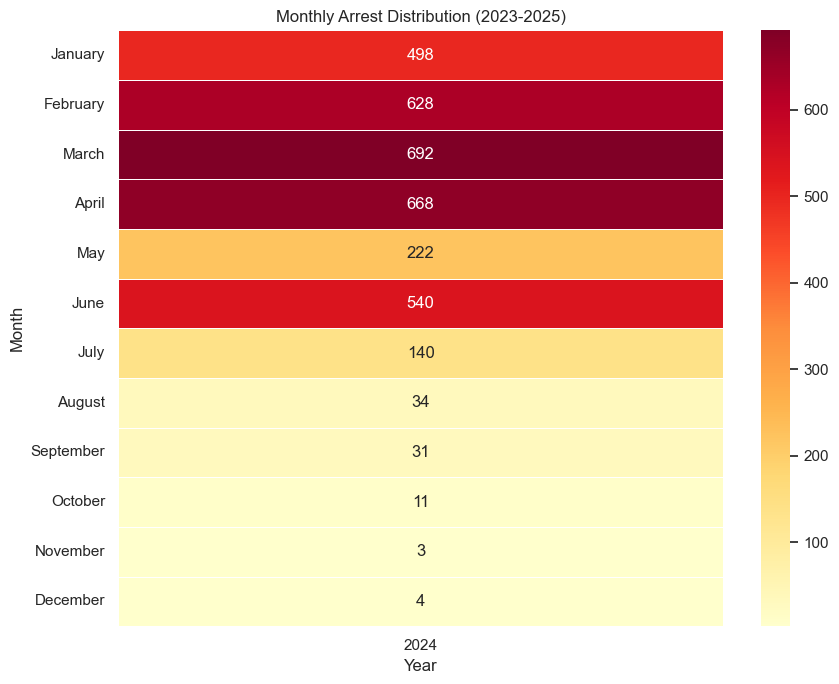

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\jason\Downloads\KS-2024\Wichita_Crime_Data_2.csv")


sns.set_theme(style="whitegrid", palette="muted")
# Style

df["arrest_date"] = pd.to_datetime(
    df["arrest_date"],
    errors="coerce"
)


df["month"] = df["arrest_date"].dt.month

df["month_name"] = df["arrest_date"].dt.month_name() 

monthly_arrests = df.groupby(
    ["data_year", "month"]
).size().reset_index(name="arrest_count")


monthly_arrests["month_name"] = pd.to_datetime(
    monthly_arrests["month"],
    format="%m"
).dt.month_name()

import calendar

monthly_data = df.pivot_table(
    index="month",
    columns="data_year",
    values="arrestee_id",
    aggfunc="count"
)

monthly_data.index = monthly_data.index.map(lambda x: calendar.month_name[int(x)])

plt.figure(figsize=(9, 7))

sns.heatmap(
    monthly_data,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Monthly Arrest Distribution (2023-2025)")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()
plt.show()